# Customer Churn Prediction for a Telecom Provider

**Goal:** identify customers likely to cancel next, and decide *who to contact* with a retention offer so that the campaign makes money.

**Dataset:** IBM Telco Customer Churn (7,043 customers, 21 columns). Download it from Kaggle and place it in `data/` (see `data/README.md`).

**Approach**
1. Validate and clean the data
2. Explore churn drivers
3. Baseline (logistic regression) vs. gradient boosting, with proper cross-validation
4. Choose the decision threshold by **expected campaign profit**, not by accuracy
5. Evaluate once on a held-out test set
6. Explain the model and turn it into recommendations

## 1. Setup

In [1]:
import warnings; warnings.filterwarnings("ignore")
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_predict, RandomizedSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import (roc_auc_score, average_precision_score, confusion_matrix,
                             precision_score, recall_score, RocCurveDisplay, PrecisionRecallDisplay)
from sklearn.inspection import permutation_importance, PartialDependenceDisplay

RANDOM_STATE = 42
DATA_PATH = Path("../data/WA_Fn-UseC_-Telco-Customer-Churn.csv")
sns.set_theme(style="whitegrid")

## 2. Load and validate the data

In [2]:
df = pd.read_csv(DATA_PATH)
print(df.shape)
df.head()

(7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
# TotalCharges is read as text because a few rows contain blank strings
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

print("Missing TotalCharges:", df["TotalCharges"].isna().sum())
print("Duplicate customerIDs:", df["customerID"].duplicated().sum())
df.loc[df["TotalCharges"].isna(), ["customerID", "tenure", "MonthlyCharges", "TotalCharges"]]

Missing TotalCharges: 11
Duplicate customerIDs: 0


,customerID,tenure,MonthlyCharges,TotalCharges
488,4472-LVYGI,0,52.55,NaN
753,3115-CZMZD,0,20.25,NaN
936,5709-LVOEQ,0,80.85,NaN
1082,4367-NUYAO,0,25.75,NaN
1340,1371-DWPAZ,0,56.05,NaN
3331,7644-OMVMY,0,19.85,NaN
3826,3213-VVOLG,0,25.35,NaN
4380,2520-SGTTA,0,20.00,NaN
5218,2923-ARZLG,0,19.70,NaN
6670,4075-WKNIU,0,73.35,NaN


The rows with missing `TotalCharges` should all have `tenure == 0`, i.e. customers who have not yet been billed. Setting `TotalCharges = 0` for them is a defensible choice. The check below confirms it before we apply it.

In [4]:
missing_mask = df["TotalCharges"].isna()
print("All missing rows have tenure 0:", bool((df.loc[missing_mask, "tenure"] == 0).all()))
df.loc[df["tenure"] == 0, "TotalCharges"] = 0.0

df["churn"] = (df["Churn"] == "Yes").astype(int)
print(f"Churn rate: {df['churn'].mean():.1%}  ->  imbalanced, so accuracy would be misleading")

All missing rows have tenure 0: True
Churn rate: 26.5%  ->  imbalanced, so accuracy would be misleading


## 3. Exploratory analysis

In [5]:
df["tenure_bin"] = pd.cut(df["tenure"], bins=[-1, 6, 12, 24, 48, 72],
                          labels=["0-6", "7-12", "13-24", "25-48", "49-72"])

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, col in zip(axes.ravel(), ["Contract", "InternetService", "PaymentMethod", "tenure_bin"]):
    rate = df.groupby(col, observed=True)["churn"].mean().sort_values(ascending=False) * 100
    sns.barplot(x=rate.values, y=rate.index.astype(str), ax=ax, color="#4C72B0")
    ax.axvline(df["churn"].mean() * 100, color="red", ls="--", lw=1)
    ax.set_title(f"Churn rate by {col} (%)"); ax.set_xlabel(""); ax.set_ylabel("")
plt.tight_layout(); plt.show()

<Figure size 1200x800 with 4 Axes>

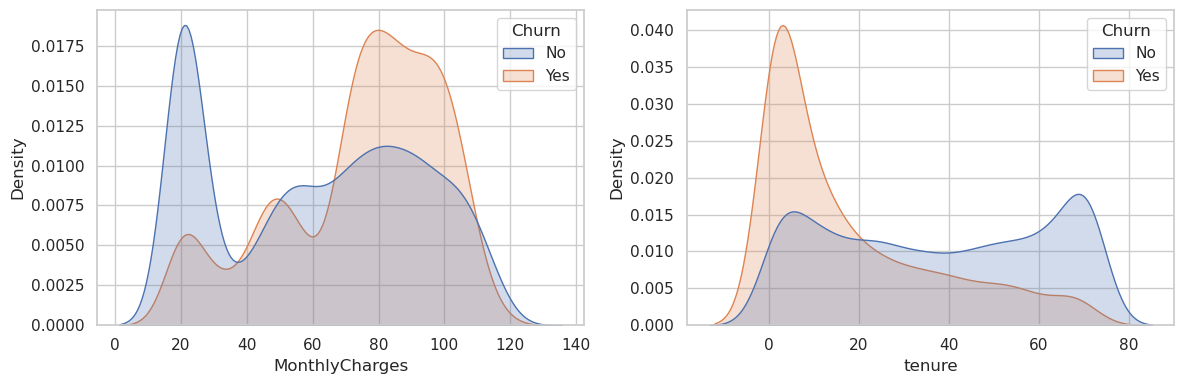

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.kdeplot(data=df, x="MonthlyCharges", hue="Churn", common_norm=False, fill=True, ax=axes[0])
sns.kdeplot(data=df, x="tenure", hue="Churn", common_norm=False, fill=True, ax=axes[1])
plt.tight_layout(); plt.show()

**Findings (from the run documented in this notebook):**
- **Contract is the strongest signal.** Month-to-month customers churn at **42.7%**, vs. 11.3% on one-year and only 2.8% on two-year contracts (overall churn: 26.5%).
- **Payment method matters.** Electronic-check payers churn at **45.3%**, while automatic payers sit at 15-17%. Paperless billing also splits clearly: 33.6% vs. 16.3%.
- **Fiber-optic customers churn at 41.9%**, more than double DSL (19.0%) — high price, unmet expectations, or both.
- **Risk is front-loaded.** Customers in their first 6 months churn at **52.9%**; by 49-72 months it falls to 9.5%. The tenure density plot confirms churners pile up at low tenure and high monthly charges (~$70-105).

## 4. Feature engineering and train/test split

The test set is split off **before** any fitting and is used exactly once at the end. All preprocessing lives inside a scikit-learn `Pipeline`, so nothing leaks from validation folds or from the test set.

In [7]:
ADDON_COLS = ["OnlineSecurity", "OnlineBackup", "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies"]

data = df.drop(columns=["customerID", "Churn", "tenure_bin"]).copy()
data["num_addons"] = (df[ADDON_COLS] == "Yes").sum(axis=1)
data["is_autopay"] = df["PaymentMethod"].str.contains("automatic", case=False).astype(int)
data["charge_per_tenure_month"] = data["TotalCharges"] / data["tenure"].clip(lower=1)

X = data.drop(columns="churn")
num_features = X.select_dtypes(include="number").columns
X[num_features] = X[num_features].astype(float)   # float dtype keeps partial-dependence plots happy
y = data["churn"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
print(X_train.shape, X_test.shape, f"| churn rate train {y_train.mean():.1%} / test {y_test.mean():.1%}")

(5634, 22) (1409, 22) | churn rate train 26.5% / test 26.5%


In [8]:
num_cols = X.select_dtypes(include="number").columns.tolist()
cat_cols = X.select_dtypes(exclude="number").columns.tolist()
print("Numeric:", num_cols); print("Categorical:", cat_cols)

preprocess = ColumnTransformer([
    ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols),
])

Numeric: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges', 'num_addons', 'is_autopay', 'charge_per_tenure_month']
Categorical: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


## 5. Modeling: baseline vs. gradient boosting

Metrics are **ROC-AUC** and **PR-AUC** (average precision). PR-AUC is the more honest metric here because only about a quarter of customers churn.

In [9]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

logreg = Pipeline([("prep", preprocess),
                   ("clf", LogisticRegression(max_iter=2000, class_weight="balanced"))])

oof_lr = cross_val_predict(logreg, X_train, y_train, cv=cv, method="predict_proba")[:, 1]
print(f"Logistic regression (5-fold OOF)  ROC-AUC {roc_auc_score(y_train, oof_lr):.3f} | PR-AUC {average_precision_score(y_train, oof_lr):.3f}")

Logistic regression (5-fold OOF)  ROC-AUC 0.845 | PR-AUC 0.655


In [10]:
hgb = Pipeline([("prep", preprocess),
                ("clf", HistGradientBoostingClassifier(early_stopping=True, random_state=RANDOM_STATE))])

param_dist = {
    "clf__learning_rate": [0.03, 0.05, 0.1],
    "clf__max_depth": [3, 4, 6, None],
    "clf__max_leaf_nodes": [15, 31],
    "clf__min_samples_leaf": [20, 40, 80],
    "clf__l2_regularization": [0.0, 0.1, 1.0],
    "clf__max_iter": [200, 400],
}
search = RandomizedSearchCV(hgb, param_dist, n_iter=15, scoring="average_precision",
                            cv=cv, random_state=RANDOM_STATE, n_jobs=-1)
search.fit(X_train, y_train)
print("Best params:", search.best_params_)
print(f"Gradient boosting (CV PR-AUC): {search.best_score_:.3f}")

Best params: {'clf__min_samples_leaf': 40, 'clf__max_leaf_nodes': 31, 'clf__max_iter': 400, 'clf__max_depth': 4, 'clf__learning_rate': 0.05, 'clf__l2_regularization': 0.0}
Gradient boosting (CV PR-AUC): 0.666


**Model choice rule:** if gradient boosting does not clearly beat the logistic regression baseline, prefer the logistic regression. It is simpler, easier to explain to the business, and cheaper to maintain. Compare the two numbers above before continuing.

In [11]:
final_model = search.best_estimator_      # already refit on the full training set
oof_hgb = cross_val_predict(final_model, X_train, y_train, cv=cv, method="predict_proba")[:, 1]
print(f"Gradient boosting (5-fold OOF)    ROC-AUC {roc_auc_score(y_train, oof_hgb):.3f} | PR-AUC {average_precision_score(y_train, oof_hgb):.3f}")

Gradient boosting (5-fold OOF)    ROC-AUC 0.847 | PR-AUC 0.660


## 6. Choosing the threshold by business value

A model score is only useful if it drives a decision. We contact every customer whose churn probability is at or above a threshold, and pick the threshold that maximizes **expected campaign profit** on the *training out-of-fold predictions* (never on the test set).

> **All numbers below are illustrative assumptions.** Replace them with the company's real retention cost, offer success rate and margin.

Best threshold: 0.17  | expected profit (train OOF): 103,066
Contact everyone: 76,649  | Contact nobody: 0


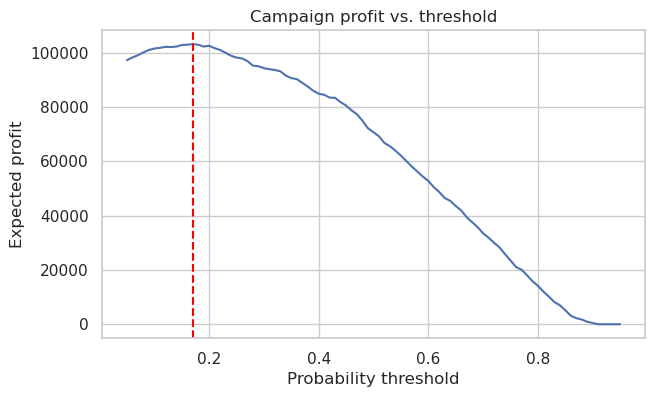

In [12]:
RETENTION_COST = 15.0        # cost of contacting + discounting one customer
OFFER_SUCCESS_RATE = 0.30    # share of would-be churners who stay after the offer
VALUE_MONTHS = 12            # horizon of revenue saved per retained customer
MARGIN = 0.40                # share of revenue that is profit

def expected_profit(y_true, proba, monthly_charges, threshold):
    contacted = proba >= threshold
    saved_value = VALUE_MONTHS * np.asarray(monthly_charges) * MARGIN
    gain = np.where(np.asarray(y_true) == 1, OFFER_SUCCESS_RATE * saved_value, 0.0)
    return float(np.sum((gain - RETENTION_COST)[contacted]))

thresholds = np.linspace(0.05, 0.95, 91)
mc_train = X_train["MonthlyCharges"].values
profits = np.array([expected_profit(y_train, oof_hgb, mc_train, t) for t in thresholds])

best_idx = int(profits.argmax())
BEST_T = float(thresholds[best_idx])
print(f"Best threshold: {BEST_T:.2f}  | expected profit (train OOF): {profits[best_idx]:,.0f}")
print(f"Contact everyone: {expected_profit(y_train, oof_hgb, mc_train, 0.0):,.0f}  | Contact nobody: 0")

plt.figure(figsize=(7, 4))
plt.plot(thresholds, profits); plt.axvline(BEST_T, color="red", ls="--")
plt.xlabel("Probability threshold"); plt.ylabel("Expected profit"); plt.title("Campaign profit vs. threshold")
plt.show()

Profit is sensitive to the assumptions, so check how stable the best threshold is when the offer success rate or the retention cost changes. A flat curve around the optimum means the decision is robust.

## 7. Final evaluation on the held-out test set (used once)

ROC-AUC 0.846 | PR-AUC 0.662
At threshold 0.17: precision 0.445 | recall 0.888
Customers contacted: 746 of 1409
Expected profit (test): 24,076


Baseline logistic regression on test: ROC-AUC 0.842 | PR-AUC 0.632


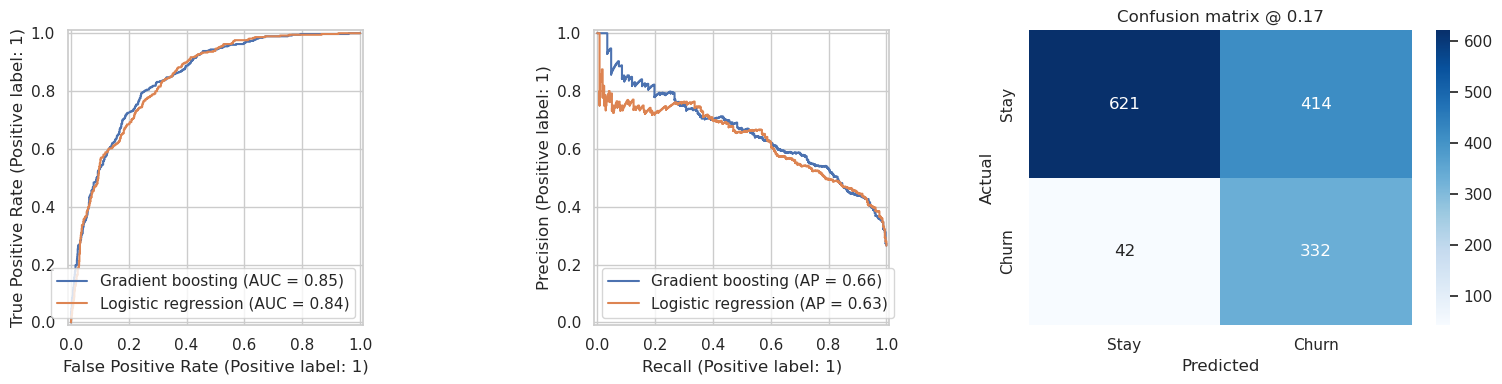

In [13]:
test_proba = final_model.predict_proba(X_test)[:, 1]
test_pred = (test_proba >= BEST_T).astype(int)

print(f"ROC-AUC {roc_auc_score(y_test, test_proba):.3f} | PR-AUC {average_precision_score(y_test, test_proba):.3f}")
print(f"At threshold {BEST_T:.2f}: precision {precision_score(y_test, test_pred):.3f} | recall {recall_score(y_test, test_pred):.3f}")
print(f"Customers contacted: {test_pred.sum()} of {len(test_pred)}")
print(f"Expected profit (test): {expected_profit(y_test, test_proba, X_test['MonthlyCharges'].values, BEST_T):,.0f}")

lr_test = logreg.fit(X_train, y_train).predict_proba(X_test)[:, 1]
print(f"Baseline logistic regression on test: ROC-AUC {roc_auc_score(y_test, lr_test):.3f} | PR-AUC {average_precision_score(y_test, lr_test):.3f}")

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
RocCurveDisplay.from_predictions(y_test, test_proba, ax=axes[0], name="Gradient boosting")
RocCurveDisplay.from_predictions(y_test, lr_test, ax=axes[0], name="Logistic regression")
PrecisionRecallDisplay.from_predictions(y_test, test_proba, ax=axes[1], name="Gradient boosting")
PrecisionRecallDisplay.from_predictions(y_test, lr_test, ax=axes[1], name="Logistic regression")
sns.heatmap(confusion_matrix(y_test, test_pred), annot=True, fmt="d", cmap="Blues", ax=axes[2],
            xticklabels=["Stay", "Churn"], yticklabels=["Stay", "Churn"])
axes[2].set_title(f"Confusion matrix @ {BEST_T:.2f}"); axes[2].set_xlabel("Predicted"); axes[2].set_ylabel("Actual")
plt.tight_layout()
fig.savefig("../images/evaluation.png", dpi=150, bbox_inches="tight")
plt.show()

In [14]:
# Lift table: how many churners do we catch by contacting the top-scored customers?
lift = pd.DataFrame({"y": y_test.values, "p": test_proba}).sort_values("p", ascending=False).reset_index(drop=True)
lift["decile"] = pd.qcut(lift.index, 10, labels=range(1, 11))
tbl = lift.groupby("decile", observed=True).agg(customers=("y", "size"), churners=("y", "sum"))
tbl["churn_rate_%"] = (tbl["churners"] / tbl["customers"] * 100).round(1)
tbl["cum_churners_captured_%"] = (tbl["churners"].cumsum() / tbl["churners"].sum() * 100).round(1)
tbl

,customers,churners,churn_rate_%,cum_churners_captured_%
decile,,,,
1,141,106,75.2,28.3
2,141,82,58.2,50.3
3,141,61,43.3,66.6
4,141,50,35.5,79.9
5,141,24,17.0,86.4
6,140,29,20.7,94.1
7,141,10,7.1,96.8
8,141,8,5.7,98.9
9,141,3,2.1,99.7


## 8. Explaining the model

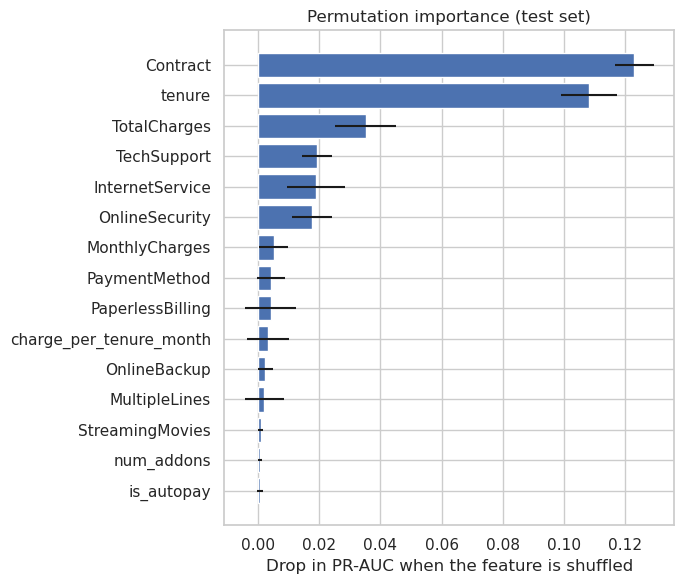

In [15]:
perm = permutation_importance(final_model, X_test, y_test, scoring="average_precision",
                              n_repeats=10, random_state=RANDOM_STATE, n_jobs=-1)
imp = pd.Series(perm.importances_mean, index=X_test.columns).sort_values().tail(15)
imp_std = pd.Series(perm.importances_std, index=X_test.columns)[imp.index]

plt.figure(figsize=(7, 6))
plt.barh(imp.index, imp.values, xerr=imp_std.values, color="#4C72B0")
plt.xlabel("Drop in PR-AUC when the feature is shuffled"); plt.title("Permutation importance (test set)")
plt.tight_layout(); plt.show()

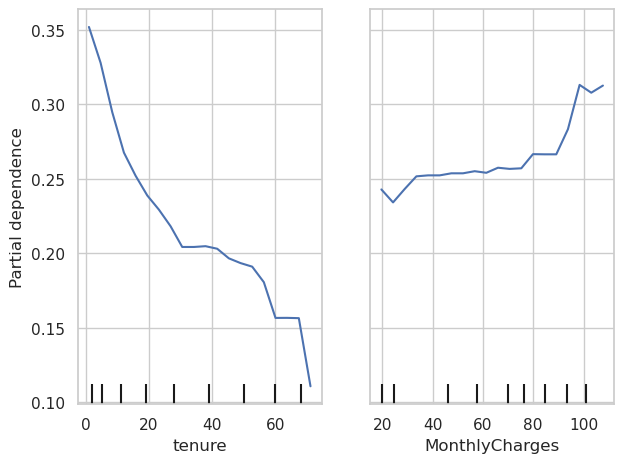

In [16]:
PartialDependenceDisplay.from_estimator(final_model, X_test, ["tenure", "MonthlyCharges"], grid_resolution=20)
plt.tight_layout(); plt.show()

Permutation importance tells you *which* features matter; partial dependence shows *how* the predicted churn probability moves with them. Both are model-agnostic.

**Top 3 drivers in this run (drop in test PR-AUC when shuffled):**
1. **Contract** (~0.12) — month-to-month contracts dominate churn risk, matching the EDA gap (42.7% vs. 2.8%).
2. **Tenure** (~0.11) — the longer a customer stays, the less likely they are to leave; risk concentrates in the first months.
3. **TotalCharges** (~0.03) — cumulative spend adds signal beyond monthly charges alone; TechSupport, InternetService and OnlineSecurity follow at ~0.02 each, so lacking support/protection add-ons also flags risk.

## 9. Save the model

In [17]:
Path("../models").mkdir(exist_ok=True)
joblib.dump(final_model, "../models/churn_model.joblib")
with open("../models/threshold.json", "w") as f:
    json.dump({"threshold": BEST_T}, f)
print("Saved model and threshold")

Saved model and threshold


## 10. Limitations and next steps

- The dataset is a **single snapshot**; there are no timestamps, so we cannot test how the model behaves on future customers (no temporal validation).
- Business parameters (cost, success rate, margin) are assumptions, not measured values.
- Predicting *who* will churn is not the same as knowing *who will respond* to an offer. An **uplift model** or an A/B test would answer that.
- Probabilities were not explicitly calibrated; if they are used as absolute risk numbers, add calibration.
- Next steps: SHAP explanations, fairness check across demographic groups, monitoring plan for drift.